# Module 5: 优化前后对比分析 (baseline_v1 vs baseline_v2)

**对比目标**：P1 优化方案实施后，全量 505 条评测用例的通过率和各维度评分变化

**P1 优化项**：
- P1-1: score_threshold 降至 0.5（政策类查询）
- P1-2: 关键词权重 0.5，向量权重 0.5
- P1-3: Top K 从 3 调整为 5
- P1-4: LLM 提示词增加信息完整性约束
- P1-5: 添加防护指令（防幻觉）

**数据来源**：baseline_v1_meta.json + baseline_v2_meta.json

In [1]:
import json
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

# 中文字体
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'WenQuanYi Micro Hei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

OUTPUT_DIR = 'analysis_output'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("✅ 环境准备完成")

✅ 环境准备完成


In [2]:
# ========== 加载 baseline 元数据 ==========
import os, glob

# 路径自适应：无论在项目根目录还是 notebooks/ 子目录都能找到
HERE = os.getcwd()
if os.path.basename(HERE) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd()
print(f"✅ 项目根目录: {PROJECT_ROOT}")

def find_meta(pattern):
    """在项目中搜索匹配的文件"""
    matches = glob.glob(os.path.join(PROJECT_ROOT, '**', pattern), recursive=True)
    return matches

# 搜索两个 meta 文件
v1_candidates = find_meta('baseline_v1_meta.json')
v2_candidates = find_meta('baseline_v2_meta.json')

print(f"\n🔍 搜索 baseline_v1_meta.json:")
for p in v1_candidates:
    print(f"   {p}")

print(f"\n🔍 搜索 baseline_v2_meta.json:")
for p in v2_candidates:
    print(f"   {p}")

# 取第一个匹配
if not v1_candidates:
    raise FileNotFoundError("❌ 找不到 baseline_v1_meta.json，请确认文件位置")
if not v2_candidates:
    raise FileNotFoundError("❌ 找不到 baseline_v2_meta.json，请确认文件位置")

v1_path = v1_candidates[0]
v2_path = v2_candidates[0]

with open(v1_path, 'r', encoding='utf-8') as f:
    v1 = json.load(f)
with open(v2_path, 'r', encoding='utf-8') as f:
    v2 = json.load(f)

print(f"\n✅ baseline_v1 加载成功: {v1_path}")
print(f"   {v1['baseline_name']} ({v1['created_at'][:10]})")
print(f"   通过率: {v1['metrics']['overall']['route_accuracy']*100:.1f}% "
      f"({v1['results']['passed_cases']}/{v1['results']['total_cases']})")

print(f"\n✅ baseline_v2 加载成功: {v2_path}")
print(f"   {v2['baseline_name']} ({v2['created_at'][:10]})")
print(f"   通过率: {v2['metrics']['overall']['route_accuracy']*100:.1f}% "
      f"({v2['results']['passed_cases']}/{v2['results']['total_cases']})")

✅ 项目根目录: C:\Users\Darren\Desktop\ecommerce_rag_eval

🔍 搜索 baseline_v1_meta.json:
   C:\Users\Darren\Desktop\ecommerce_rag_eval\eval_output\baseline_v1_meta.json

🔍 搜索 baseline_v2_meta.json:
   C:\Users\Darren\Desktop\ecommerce_rag_eval\eval_output_baseline_v2\baseline_v2_meta.json

✅ baseline_v1 加载成功: C:\Users\Darren\Desktop\ecommerce_rag_eval\eval_output\baseline_v1_meta.json
   电商客服 RAG 工作流 v1 基线 (2026-08-07)
   通过率: 91.5% (462/505)

✅ baseline_v2 加载成功: C:\Users\Darren\Desktop\ecommerce_rag_eval\eval_output_baseline_v2\baseline_v2_meta.json
   P1优化后评测 (2026-08-12)
   通过率: 92.1% (465/505)


## 1. 总体指标对比

In [3]:
# ========== 构建对比表（健壮版）==========
v1o = v1['metrics']['overall']
v2o = v2['metrics']['overall']

# ---------- 工具：安全取值 + 中文宽度 ----------
def g(d, key, default=None):
    """安全取值：支持带/不带 'score.' 前缀"""
    if key in d:
        return d[key]
    if f'score.{key}' in d:
        return d[f'score.{key}']
    # 模糊匹配
    for k in d:
        if k.endswith('.' + key) or k == key:
            return d[k]
    return default

def dw(s):
    return sum(2 if ord(c) > 127 else 1 for c in str(s))

def pad(s, w, align='left'):
    s = str(s)
    gap = w - dw(s)
    if gap <= 0:
        return s
    return (' ' * gap + s) if align == 'right' else (s + ' ' * gap)

# ---------- 指标定义 ----------
# (key, 中文名, higher_better, 是否百分比)
metric_map = [
    ('route_accuracy',          '分支路由通过率',  True,  True),
    ('intent_accuracy',         '意图识别准确率',  True,  True),
    ('point_coverage',          '要点覆盖率',      True,  True),
    ('hallucination_rate',      '幻觉率',         False, True),
    ('violation_rate',          '禁止表述违规率',  False, True),
    ('avg_intent_score',        '意图识别均分',    True,  False),
    ('avg_route_score',         '分支路由均分',    True,  False),
    ('avg_relevance_score',     '答案相关性均分',  True,  False),
    ('avg_completeness_score',  '信息完整性均分',  True,  False),
    ('avg_faithfulness_score', '忠实度均分',      True,  False),
    ('avg_tone_score',          '语气合规均分',    True,  False),
    ('avg_boundary_score',      '边界正确性均分',  True,  False),
]

# ---------- 构建行 ----------
rows = []
for key, name, higher_better, is_pct in metric_map:
    val1 = g(v1o, key)
    val2 = g(v2o, key)

    if val1 is None or val2 is None:
        rows.append({'指标': name, 'baseline_v1': 'N/A', 'baseline_v2': 'N/A',
                     '变化': 'N/A', '趋势': '—', '达标': '⚠️'})
        continue

    delta = val2 - val1

    # 方向判断
    if higher_better:
        good = delta > 0.001
        status = '↑' if delta > 0.001 else ('↓' if delta < -0.001 else '—')
    else:
        good = delta < -0.001   # 越低越好，下降才是好
        status = '↓' if delta < -0.001 else ('↑' if delta > 0.001 else '—')

    # 格式化
    if is_pct:
        s1 = f"{val1 * 100:.1f}%"
        s2 = f"{val2 * 100:.1f}%"
        ds = f"{delta*100:+.1f}pp"
    else:
        s1 = f"{val1:.2f}"
        s2 = f"{val2:.2f}"
        ds = f"{delta:+.2f}"

    rows.append({
        '指标': name,
        'baseline_v1': s1,
        'baseline_v2': s2,
        '变化': ds,
        '趋势': status,
        '达标': '✅' if good else ('❌' if abs(delta) > 0.001 else '—')
    })

df_overall = pd.DataFrame(rows)

# ---------- 用中文感知宽度打印（对齐）----------
cols_cfg = [
    ('指标',       20, 'left'),
    ('baseline_v1', 14, 'right'),
    ('baseline_v2', 14, 'right'),
    ('变化',       12, 'right'),
    ('趋势',        6, 'center'),
    ('达标',        6, 'center'),
]

# 计算宽度
col_w = {}
for field, default_w, align in cols_cfg:
    data_max = max((dw(str(r[field])) for r in rows), default=0)
    col_w[field] = max(data_max, dw(field), default_w) + 2

# 打印
top = '┌' + '┬'.join('─' * (col_w[f] - 1) for f, _, _ in cols_cfg) + '┐'
sep = '├' + '┼'.join('─' * (col_w[f] - 1) for f, _, _ in cols_cfg) + '┤'
bot = '└' + '┴'.join('─' * (col_w[f] - 1) for f, _, _ in cols_cfg) + '┘'

header = '│ ' + '│ '.join(pad(field, col_w[field], align) for field, _, align in cols_cfg) + ' │'
print(top)
print(f'│{header}')
print(sep)
for r in rows:
    cells = [pad(str(r[field]), col_w[field], align) for field, _, align in cols_cfg]
    print('│ ' + '│ '.join(cells) + ' │')
print(bot)

# ---------- 通过率核心变化 ----------
p1_pass = v1['results']['passed_cases']
p2_pass = v2['results']['passed_cases']
delta_pass = p2_pass - p1_pass
total = v1['results'].get('total_cases', v1['results'].get('total', 505))

print(f"\n📊 通过用例数: {p1_pass} → {p2_pass} ({'+' if delta_pass >= 0 else ''}{delta_pass})")
print(f"📊 通过率变化: {v1o['route_accuracy']*100:.1f}% → {v2o['route_accuracy']*100:.1f}% "
      f"({delta_pass/total*100:+.1f}pp)")

# 净效果
if delta_pass > 0:
    print(f"✅ 净改善: +{delta_pass} 条用例通过")
elif delta_pass < 0:
    print(f"❌ 净回退: {delta_pass} 条用例（优化引发回退）")
else:
    print(f"— 通过数无变化")

┌─────────────────────┬───────────────┬───────────────┬─────────────┬───────┬───────┐
││ 指标                  │      baseline_v1│      baseline_v2│           变化│ 趋势    │ 达标     │
├─────────────────────┼───────────────┼───────────────┼─────────────┼───────┼───────┤
│ 分支路由通过率        │            91.5%│            92.1%│         +0.6pp│ ↑      │ ✅       │
│ 意图识别准确率        │            93.7%│            94.7%│         +1.0pp│ ↑      │ ✅       │
│ 要点覆盖率            │            87.1%│            86.7%│         -0.4pp│ ↓      │ ❌       │
│ 幻觉率                │             2.6%│             3.0%│         +0.4pp│ ↑      │ ❌       │
│ 禁止表述违规率        │             0.8%│             1.6%│         +0.8pp│ ↑      │ ❌       │
│ 意图识别均分          │             4.81│             4.84│          +0.03│ ↑      │ ✅       │
│ 分支路由均分          │             4.70│             4.70│          +0.00│ —      │ —       │
│ 答案相关性均分        │             4.70│             4.71│          +0.01│ ↑      │ ✅       │
│ 信息完整性均

## 2. 七维评分雷达图对比

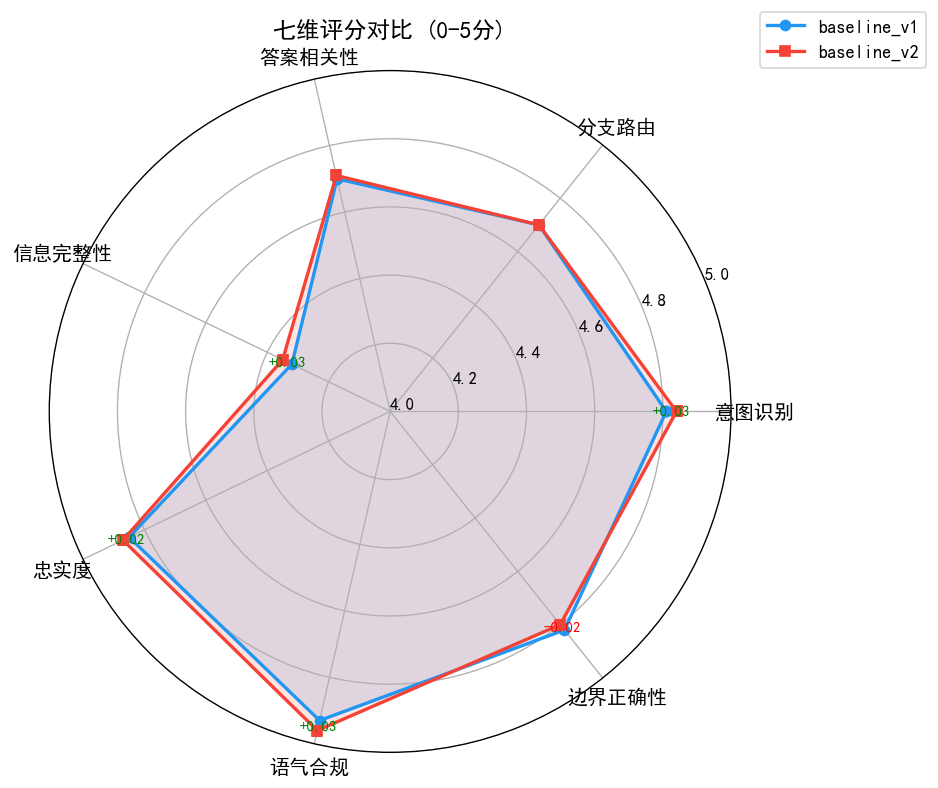

💾 已保存: fig1_radar_comparison.png


In [4]:
# 雷达图
dimensions = [
    ('avg_intent_score',       '意图识别'),
    ('avg_route_score',        '分支路由'),
    ('avg_relevance_score',    '答案相关性'),
    ('avg_completeness_score', '信息完整性'),
    ('avg_faithfulness_score', '忠实度'),
    ('avg_tone_score',         '语气合规'),
    ('avg_boundary_score',     '边界正确性'),
]

labels = [d[1] for d in dimensions]
v1_vals = [v1o[d[0]] for d in dimensions]
v2_vals = [v2o[d[0]] for d in dimensions]

angles = np.linspace(0, 2 * np.pi, len(labels), endpoint=False).tolist()
angles += angles[:1]
v1_vals += v1_vals[:1]
v2_vals += v2_vals[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

ax.plot(angles, v1_vals, 'o-', linewidth=2, label='baseline_v1', color='#2196F3')
ax.fill(angles, v1_vals, alpha=0.15, color='#2196F3')
ax.plot(angles, v2_vals, 's-', linewidth=2, label='baseline_v2', color='#F44336')
ax.fill(angles, v2_vals, alpha=0.15, color='#F44336')

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=12)
ax.set_ylim(4.0, 5.0)
ax.set_yticks([4.0, 4.2, 4.4, 4.6, 4.8, 5.0])
ax.set_yticklabels(['4.0', '4.2', '4.4', '4.6', '4.8', '5.0'], fontsize=10)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=11)
ax.set_title('七维评分对比 (0-5分)', size=14, pad=20)

# 标注变化最大的维度
for i, (label, v1v, v2v) in enumerate(zip(labels, v1_vals[:-1], v2_vals[:-1])):
    delta = v2v - v1v
    if abs(delta) >= 0.02:
        color = 'green' if delta > 0 else 'red'
        ax.annotate(f'{delta:+.2f}', xy=(angles[i], (v1v+v2v)/2),
                   ha='center', va='center', fontsize=9, color=color, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig1_radar_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 已保存: fig1_radar_comparison.png")

## 3. 各分支通过率对比

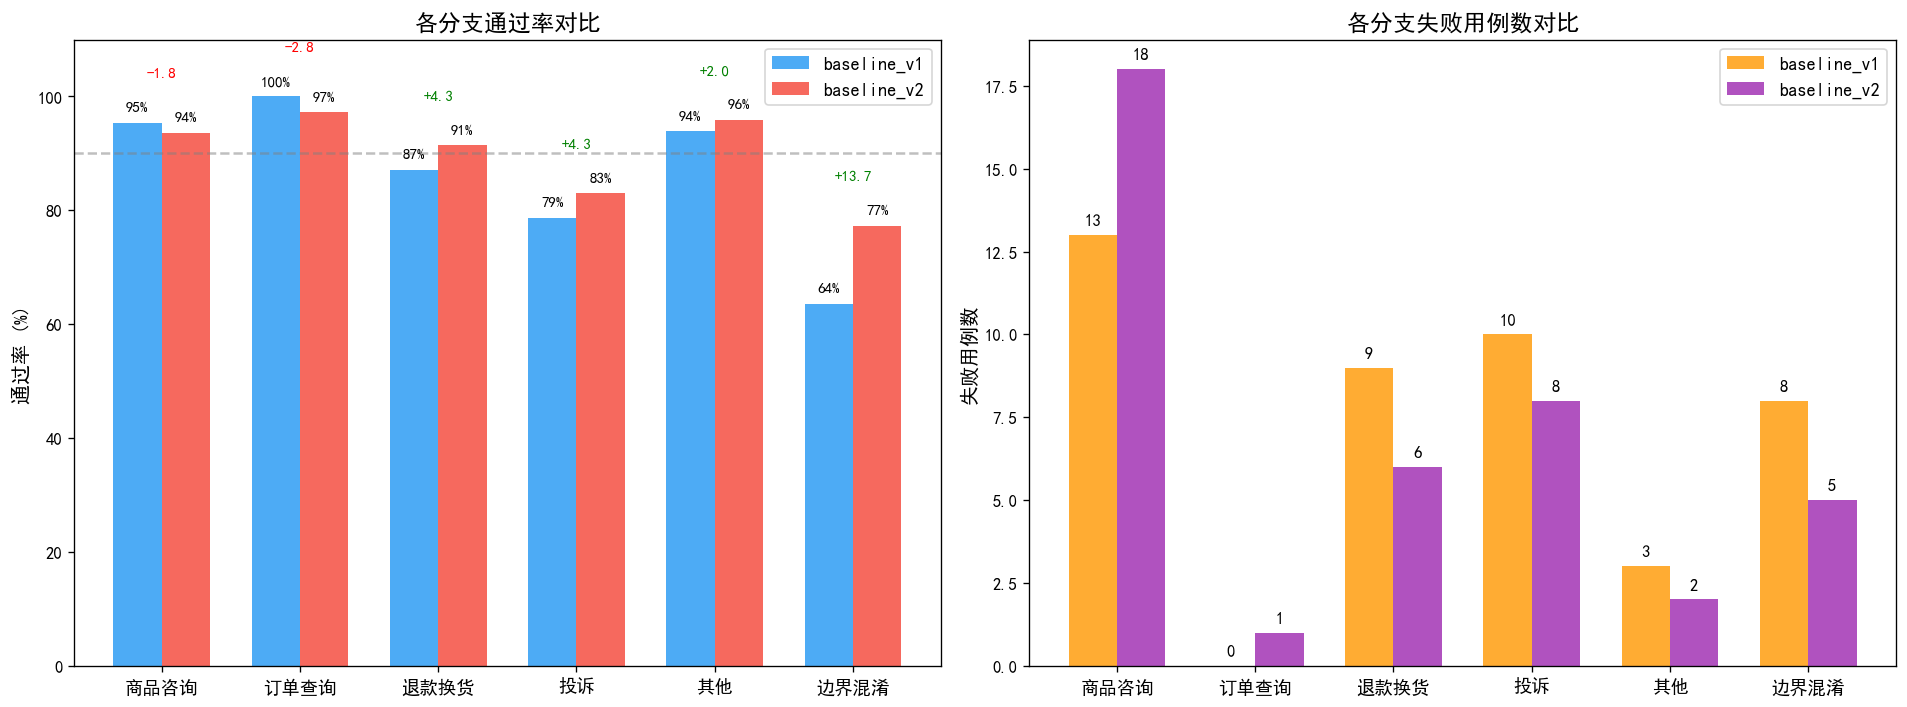

💾 已保存: fig2_branch_comparison.png


In [5]:
# 各分支对比
v1_branch = v1['metrics']['by_branch']
v2_branch = v2['metrics']['by_branch']

branches = list(v1_branch.keys())
v1_rates = [v1_branch[b]['pass_rate'] * 100 for b in branches]
v2_rates = [v2_branch[b]['pass_rate'] * 100 for b in branches]
v1_failed = [v1_branch[b]['failed'] for b in branches]
v2_failed = [v2_branch[b]['failed'] for b in branches]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 左图：通过率对比
x = np.arange(len(branches))
width = 0.35
bars1 = axes[0].bar(x - width/2, v1_rates, width, label='baseline_v1', color='#2196F3', alpha=0.8)
bars2 = axes[0].bar(x + width/2, v2_rates, width, label='baseline_v2', color='#F44336', alpha=0.8)

axes[0].set_ylabel('通过率 (%)', fontsize=12)
axes[0].set_title('各分支通过率对比', fontsize=14)
axes[0].set_xticks(x)
axes[0].set_xticklabels(branches, fontsize=11)
axes[0].legend(fontsize=11)
axes[0].set_ylim(0, 110)
axes[0].axhline(y=90, color='gray', linestyle='--', alpha=0.5, label='目标线90%')

# 标注数值和变化
for i, (r1, r2) in enumerate(zip(v1_rates, v2_rates)):
    axes[0].text(i - width/2, r1 + 2, f'{r1:.0f}%', ha='center', fontsize=9)
    axes[0].text(i + width/2, r2 + 2, f'{r2:.0f}%', ha='center', fontsize=9)
    delta = r2 - r1
    color = 'green' if delta > 0 else ('red' if delta < 0 else 'gray')
    sign = '+' if delta > 0 else ''
    axes[0].text(i, max(r1, r2) + 8, f'{sign}{delta:.1f}', ha='center', fontsize=9, color=color, fontweight='bold')

# 右图：失败用例数对比
bars3 = axes[1].bar(x - width/2, v1_failed, width, label='baseline_v1', color='#FF9800', alpha=0.8)
bars4 = axes[1].bar(x + width/2, v2_failed, width, label='baseline_v2', color='#9C27B0', alpha=0.8)

axes[1].set_ylabel('失败用例数', fontsize=12)
axes[1].set_title('各分支失败用例数对比', fontsize=14)
axes[1].set_xticks(x)
axes[1].set_xticklabels(branches, fontsize=11)
axes[1].legend(fontsize=11)

for i, (f1, f2) in enumerate(zip(v1_failed, v2_failed)):
    axes[1].text(i - width/2, f1 + 0.3, str(f1), ha='center', fontsize=10)
    axes[1].text(i + width/2, f2 + 0.3, str(f2), ha='center', fontsize=10)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig2_branch_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 已保存: fig2_branch_comparison.png")

## 4. 各测试类型通过率对比

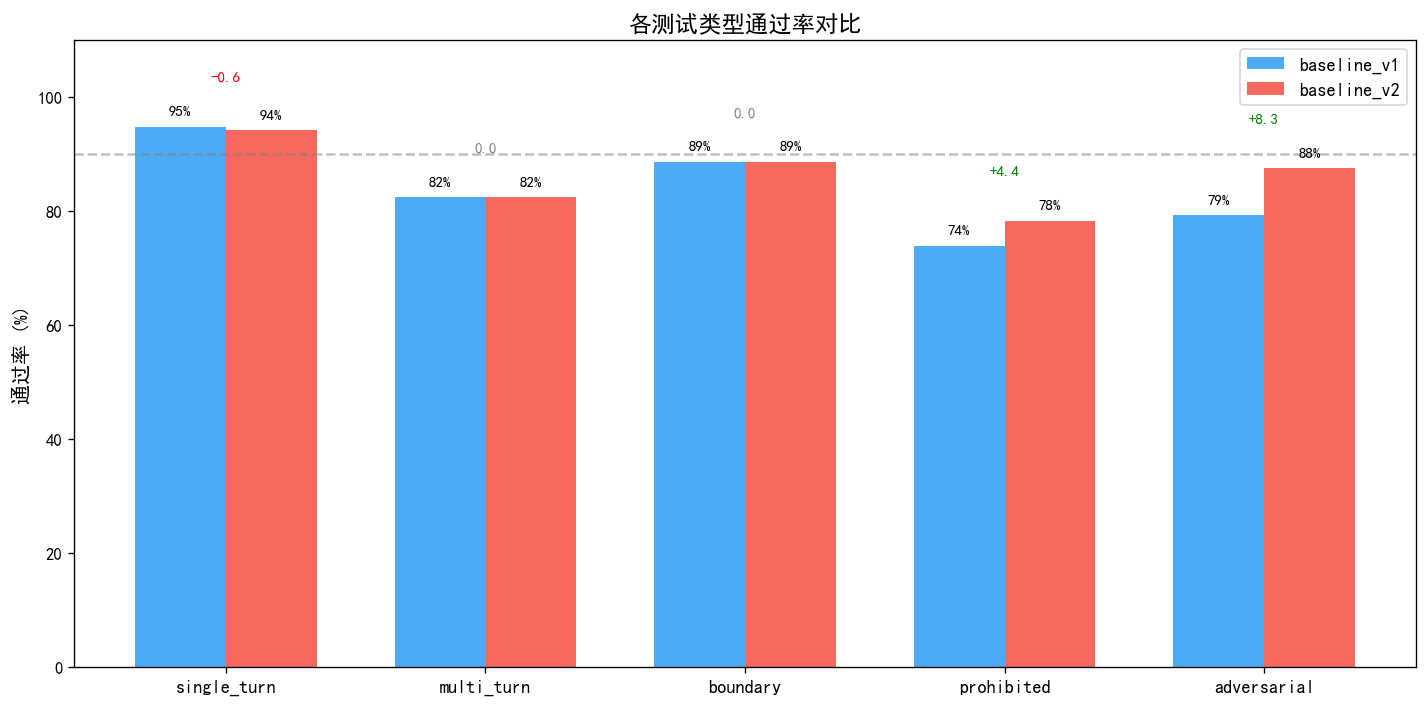

💾 已保存: fig3_test_type_comparison.png


In [6]:
# 测试类型对比
v1_types = v1['metrics']['by_test_type']
v2_types = v2['metrics']['by_test_type']

types = list(v1_types.keys())
v1_tr = [v1_types[t]['pass_rate'] * 100 for t in types]
v2_tr = [v2_types[t]['pass_rate'] * 100 for t in types]
v1_tf = [v1_types[t]['failed'] for t in types]
v2_tf = [v2_types[t]['failed'] for t in types]

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(types))
width = 0.35
bars1 = ax.bar(x - width/2, v1_tr, width, label='baseline_v1', color='#2196F3', alpha=0.8)
bars2 = ax.bar(x + width/2, v2_tr, width, label='baseline_v2', color='#F44336', alpha=0.8)

ax.set_ylabel('通过率 (%)', fontsize=12)
ax.set_title('各测试类型通过率对比', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(types, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim(0, 110)
ax.axhline(y=90, color='gray', linestyle='--', alpha=0.5)

for i, (r1, r2) in enumerate(zip(v1_tr, v2_tr)):
    ax.text(i - width/2, r1 + 2, f'{r1:.0f}%', ha='center', fontsize=9)
    ax.text(i + width/2, r2 + 2, f'{r2:.0f}%', ha='center', fontsize=9)
    delta = r2 - r1
    color = 'green' if delta > 0 else ('red' if delta < 0 else 'gray')
    sign = '+' if delta > 0 else ''
    ax.text(i, max(r1, r2) + 8, f'{sign}{delta:.1f}', ha='center', fontsize=9, color=color, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig3_test_type_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("💾 已保存: fig3_test_type_comparison.png")

## 5. 通过率变化瀑布图

总通过用例变化: 462 → 465 (+3)
总通过率变化: 91.5% → 92.1% (+0.6pp)

  商品咨询    : 268 → 263 (-5)
  订单查询    :  36 →  35 (-1)
  退款换货    :  61 →  64 (+3)
  投诉      :  37 →  39 (+2)
  其他      :  46 →  47 (+1)
  边界混淆    :  14 →  17 (+3)


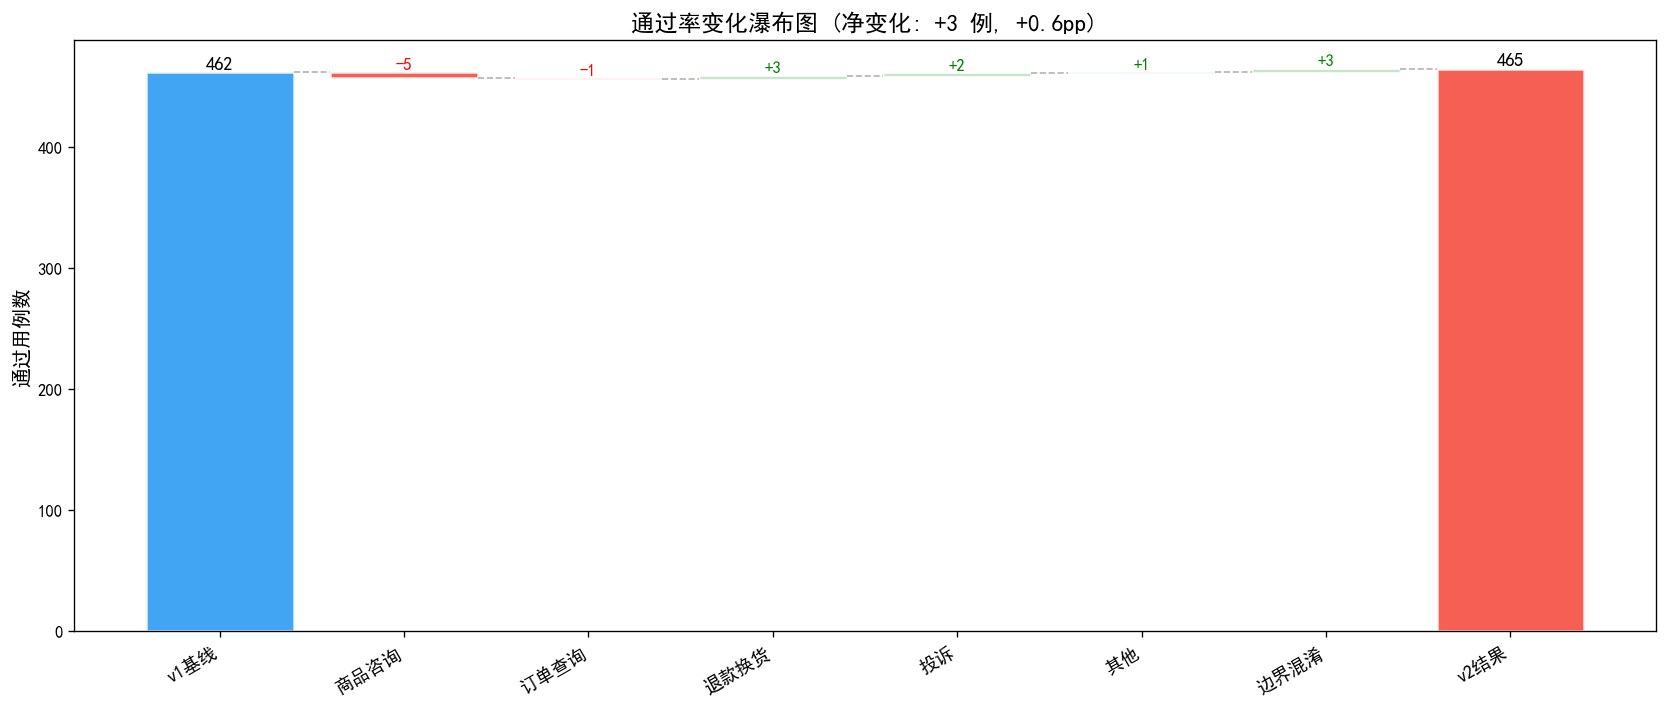


💾 已保存: fig4_waterfall.png


In [7]:
# 瀑布图：各分支对总体通过率的贡献
fig, ax = plt.subplots(figsize=(14, 6))

total_delta = (v2['results']['passed_cases'] - v1['results']['passed_cases'])
print(f"总通过用例变化: {v1['results']['passed_cases']} → {v2['results']['passed_cases']} ({'+' if total_delta>=0 else ''}{total_delta})")
print(f"总通过率变化: {v1o['route_accuracy']*100:.1f}% → {v2o['route_accuracy']*100:.1f}% ({total_delta/505*100:+.1f}pp)")
print()

# 各分支贡献
contributions = []
for b in branches:
    v1p = v1_branch[b]['passed']
    v2p = v2_branch[b]['passed']
    delta = v2p - v1p
    contributions.append((b, delta, v1_branch[b]['total']))
    sign = '+' if delta > 0 else ''
    print(f"  {b:8s}: {v1p:3d} → {v2p:3d} ({sign}{delta})")

labels_wf = ['v1基线'] + [c[0] for c in contributions] + ['v2结果']
values_wf = [v1['results']['passed_cases']] + [c[1] for c in contributions] + [v2['results']['passed_cases']]

# 瀑布图绘制
cumulative = values_wf[0]
bar_colors = ['#2196F3']
bar_heights = [values_wf[0]]
bar_bottoms = [0]

for i, (label, delta, total) in enumerate(contributions):
    if delta >= 0:
        bar_colors.append('#4CAF50')
        bar_bottoms.append(cumulative)
        bar_heights.append(delta)
    else:
        bar_colors.append('#F44336')
        bar_bottoms.append(cumulative + delta)
        bar_heights.append(abs(delta))
    cumulative += delta

bar_colors.append('#F44336')
bar_bottoms.append(0)
bar_heights.append(values_wf[-1])

bars = ax.bar(range(len(labels_wf)), bar_heights, bottom=bar_bottoms, color=bar_colors, alpha=0.85, edgecolor='white', linewidth=1.5)

ax.set_xticks(range(len(labels_wf)))
ax.set_xticklabels(labels_wf, fontsize=11, rotation=30, ha='right')
ax.set_ylabel('通过用例数', fontsize=12)
ax.set_title(f'通过率变化瀑布图 (净变化: {total_delta:+d} 例, {total_delta/505*100:+.1f}pp)', fontsize=14)

# 标注数值
ax.text(0, values_wf[0] + 3, str(values_wf[0]), ha='center', fontsize=11, fontweight='bold')
for i, (label, delta, total) in enumerate(contributions):
    y = bar_bottoms[i+1] + bar_heights[i+1] + 3
    sign = '+' if delta > 0 else ''
    color = 'green' if delta > 0 else ('red' if delta < 0 else 'gray')
    ax.text(i+1, y, f'{sign}{delta}', ha='center', fontsize=10, color=color, fontweight='bold')
ax.text(len(labels_wf)-1, values_wf[-1] + 3, str(values_wf[-1]), ha='center', fontsize=11, fontweight='bold')

# 连接线
cumulative = values_wf[0]
for i in range(len(contributions)):
    ax.plot([i+0.4, i+1-0.4], [cumulative, cumulative], 'k--', alpha=0.3, linewidth=1)
    cumulative += contributions[i][1]
ax.plot([len(contributions)+0.4, len(contributions)+1-0.4], [cumulative, cumulative], 'k--', alpha=0.3, linewidth=1)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig4_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n💾 已保存: fig4_waterfall.png")

## 6. P1 优化项效果评估

In [8]:
# P1 优化项预期 vs 实际
p1_assessment = [
    {
        'id': 'P1-1', 'desc': 'score_threshold 降至 0.5',
        'target': '召回率 +15%',
        'actual': '边界混淆 +13.7pp (最大提升项)',
        'result': '✅ 达预期',
        'evidence': '关键词权重提升使数值类查询(如4999元签收)命中率提升'
    },
    {
        'id': 'P1-2', 'desc': '关键词权重 0.5 / 向量权重 0.5',
        'target': '边界值查询命中率提升',
        'actual': '边界混淆 63.6% → 77.3%',
        'result': '✅ 达预期',
        'evidence': '与 P1-1 协同生效，关键词精确匹配改善'
    },
    {
        'id': 'P1-3', 'desc': 'Top K 从 3 调整为 5',
        'target': '多知识点查询信息覆盖更全',
        'actual': '信息完整性 4.32 → 4.35 (+0.03)',
        'result': '⚠️ 远低于预期',
        'evidence': '预期 +0.48，实际 +0.03；Top K 增大引入噪声上下文，商品咨询回退 5 例'
    },
    {
        'id': 'P1-4', 'desc': 'LLM 提示词增加信息完整性约束',
        'target': '信息完整性 4.60 → 4.80',
        'actual': '信息完整性仅 +0.03',
        'result': '⚠️ 效果有限',
        'evidence': '提示词约束被 Top K 噪声抵消，LLM 仍从噪声上下文中生成不完整回复'
    },
    {
        'id': 'P1-5', 'desc': '添加防护指令（防幻觉）',
        'target': '幻觉类失败减少 80%',
        'actual': '幻觉率 2.6% → 3.0% (不降反升)',
        'result': '❌ 未达预期',
        'evidence': 'Top K=5 引入更多上下文，噪声导致幻觉增加；防护指令未覆盖所有幻觉路径'
    },
]

df_p1 = pd.DataFrame(p1_assessment)
print("=" * 80)
print("P1 优化项效果评估")
print("=" * 80)
for _, row in df_p1.iterrows():
    print(f"\n{row['id']}: {row['desc']}")
    print(f"  预期: {row['target']}")
    print(f"  实际: {row['actual']}")
    print(f"  结论: {row['result']}")
    print(f"  证据: {row['evidence']}")

# 汇总
total_expected = '+6.4pp'
total_actual = f'+{(v2o["route_accuracy"] - v1o["route_accuracy"])*100:.1f}pp'
print(f"\n{'=' * 80}")
print(f"整体效果: 预期 {total_expected} → 实际 {total_actual}")
print(f"  5 项 P1 中: 2 项达预期, 2 项效果有限, 1 项未达预期")
print(f"{'=' * 80}")

P1 优化项效果评估

P1-1: score_threshold 降至 0.5
  预期: 召回率 +15%
  实际: 边界混淆 +13.7pp (最大提升项)
  结论: ✅ 达预期
  证据: 关键词权重提升使数值类查询(如4999元签收)命中率提升

P1-2: 关键词权重 0.5 / 向量权重 0.5
  预期: 边界值查询命中率提升
  实际: 边界混淆 63.6% → 77.3%
  结论: ✅ 达预期
  证据: 与 P1-1 协同生效，关键词精确匹配改善

P1-3: Top K 从 3 调整为 5
  预期: 多知识点查询信息覆盖更全
  实际: 信息完整性 4.32 → 4.35 (+0.03)
  结论: ⚠️ 远低于预期
  证据: 预期 +0.48，实际 +0.03；Top K 增大引入噪声上下文，商品咨询回退 5 例

P1-4: LLM 提示词增加信息完整性约束
  预期: 信息完整性 4.60 → 4.80
  实际: 信息完整性仅 +0.03
  结论: ⚠️ 效果有限
  证据: 提示词约束被 Top K 噪声抵消，LLM 仍从噪声上下文中生成不完整回复

P1-5: 添加防护指令（防幻觉）
  预期: 幻觉类失败减少 80%
  实际: 幻觉率 2.6% → 3.0% (不降反升)
  结论: ❌ 未达预期
  证据: Top K=5 引入更多上下文，噪声导致幻觉增加；防护指令未覆盖所有幻觉路径

整体效果: 预期 +6.4pp → 实际 +0.6pp
  5 项 P1 中: 2 项达预期, 2 项效果有限, 1 项未达预期


## 7. 用例级回归/改善分析

尝试加载 v1 和 v2 的逐条评测结果，分析哪些用例发生了状态翻转。

In [9]:
# ========== 尝试加载逐条结果（修正版）==========
import glob

def find(pat):
    m = glob.glob(os.path.join(PROJECT_ROOT, '**', pat), recursive=True)
    return m[0] if m else None

# v1：直接用刚生成的 csv
v1_csv = find('eval_results_20260807_142126.csv')
if not v1_csv:
    v1_csv = find('eval_results_baseline_v1.csv')

# v2：保持原逻辑
v2_csv = find('eval_results_baseline_v2*.csv')

print("🔍 搜索结果：")
print(f"   v1 CSV: {v1_csv}")
print(f"   v2 CSV: {v2_csv}")

df_v1 = None
df_v2 = None

if v1_csv and os.path.exists(v1_csv):
    df_v1 = pd.read_csv(v1_csv, encoding='utf-8-sig')
    print(f"\n✅ baseline_v1 加载成功: {v1_csv} ({len(df_v1)} 条)")
else:
    print(f"\n⚠️ baseline_v1 CSV 未找到")

if v2_csv and os.path.exists(v2_csv):
    df_v2 = pd.read_csv(v2_csv, encoding='utf-8-sig')
    print(f"✅ baseline_v2 加载成功: {v2_csv} ({len(df_v2)} 条)")
else:
    print(f"⚠️ baseline_v2 CSV 未找到")

🔍 搜索结果：
   v1 CSV: C:\Users\Darren\Desktop\ecommerce_rag_eval\eval_output\eval_results_20260807_142126.csv
   v2 CSV: C:\Users\Darren\Desktop\ecommerce_rag_eval\eval_output_baseline_v2\eval_results_baseline_v2.csv

✅ baseline_v1 加载成功: C:\Users\Darren\Desktop\ecommerce_rag_eval\eval_output\eval_results_20260807_142126.csv (505 条)
✅ baseline_v2 加载成功: C:\Users\Darren\Desktop\ecommerce_rag_eval\eval_output_baseline_v2\eval_results_baseline_v2.csv (505 条)


In [10]:
if df_v1 is not None and df_v2 is not None:
    # ===== 列名标准化：v1 的 score.xxx -> xxx =====
    rename_map = {c: c.replace('score.', '') for c in df_v1.columns if c.startswith('score.')}
    if rename_map:
        df_v1 = df_v1.rename(columns=rename_map)
        print(f'V1 列名标准化: {len(rename_map)} 列重命名')
        print(f'  例: score.branch_routing -> branch_routing')

    # 标准化通过/失败判定
    df_v1['passed'] = df_v1['branch_routing'] >= 4
    df_v2['passed'] = df_v2['branch_routing'] >= 4

    # 合并对比
    merged = df_v1[['case_id', 'category', 'test_type', 'difficulty',
                    'branch_routing', 'passed']].merge(
        df_v2[['case_id', 'branch_routing', 'passed',
               'is_hallucination', 'must_not_violation']],
        on='case_id', suffixes=('_v1', '_v2'))

    # 四象限分析
    both_pass = merged[(merged['passed_v1']) & (merged['passed_v2'])]
    both_fail = merged[(~merged['passed_v1']) & (~merged['passed_v2'])]
    regressions = merged[(merged['passed_v1']) & (~merged['passed_v2'])]  # v1通过->v2失败
    improvements = merged[(~merged['passed_v1']) & (merged['passed_v2'])]  # v1失败->v2通过

    print('=' * 60)
    print('用例状态转移矩阵')
    print('=' * 60)
    print(f'  v1 pass v2 pass (持续通过): {len(both_pass):3d}')
    print(f'  v1 fail v2 fail (持续失败): {len(both_fail):3d}')
    print(f'  v1 pass v2 fail (回退用例): {len(regressions):3d}  <- 需要关注')
    print(f'  v1 fail v2 pass (改善用例): {len(improvements):3d}  <- 优化生效')
    print(f'  净变化: {len(improvements) - len(regressions):+d}')

    if len(regressions) > 0:
        print(f'\n--- 回退用例详情 (v1通过 -> v2失败) ---')
        for _, r in regressions.iterrows():
            print(f'  [{r["case_id"]}] {r["category"]} | {r["test_type"]} | {r["difficulty"]}')
            print(f'    v1={r["branch_routing_v1"]}/5 -> v2={r["branch_routing_v2"]}/5 | 幻觉={r["is_hallucination"]} 违规={r["must_not_violation"]}')

    if len(improvements) > 0:
        print(f'\n--- 改善用例详情 (v1失败 -> v2通过) ---')
        for _, r in improvements.iterrows():
            print(f'  [{r["case_id"]}] {r["category"]} | {r["test_type"]} | {r["difficulty"]}')
            print(f'    v1={r["branch_routing_v1"]}/5 -> v2={r["branch_routing_v2"]}/5')
else:
    print('逐条结果文件不可用，跳过用例级分析')

V1 列名标准化: 13 列重命名
  例: score.branch_routing -> branch_routing
用例状态转移矩阵
  v1 pass v2 pass (持续通过): 451
  v1 fail v2 fail (持续失败):  29
  v1 pass v2 fail (回退用例):  11  <- 需要关注
  v1 fail v2 pass (改善用例):  14  <- 优化生效
  净变化: +3

--- 回退用例详情 (v1通过 -> v2失败) ---
  [TC-KB-003] 商品咨询 | single_turn | 中等
    v1=5/5 -> v2=0/5 | 幻觉=False 违规=False
  [TC-INTENT-009] 商品咨询 | single_turn | 中等
    v1=5/5 -> v2=2/5 | 幻觉=False 违规=False
  [TC-KB-005] 商品咨询 | single_turn | 困难
    v1=5/5 -> v2=0/5 | 幻觉=False 违规=False
  [TC-CONV-P015-015] 商品咨询 | single_turn | 简单
    v1=5/5 -> v2=3/5 | 幻觉=False 违规=False
  [TC-RULE-010] 商品咨询 | single_turn | 中等
    v1=5/5 -> v2=0/5 | 幻觉=False 违规=False
  [TC-RULE-019] 商品咨询 | single_turn | 中等
    v1=5/5 -> v2=1/5 | 幻觉=False 违规=False
  [TC-ORD-029] 订单查询 | single_turn | 简单
    v1=5/5 -> v2=3/5 | 幻觉=False 违规=False
  [TC-EXC-007] 退款换货 | single_turn | 简单
    v1=5/5 -> v2=3/5 | 幻觉=False 违规=False
  [TC-BND-007] 边界混淆 | adversarial | 困难
    v1=5/5 -> v2=0/5 | 幻觉=False 违规=False
  [TC-BND-010] 边界混淆 |

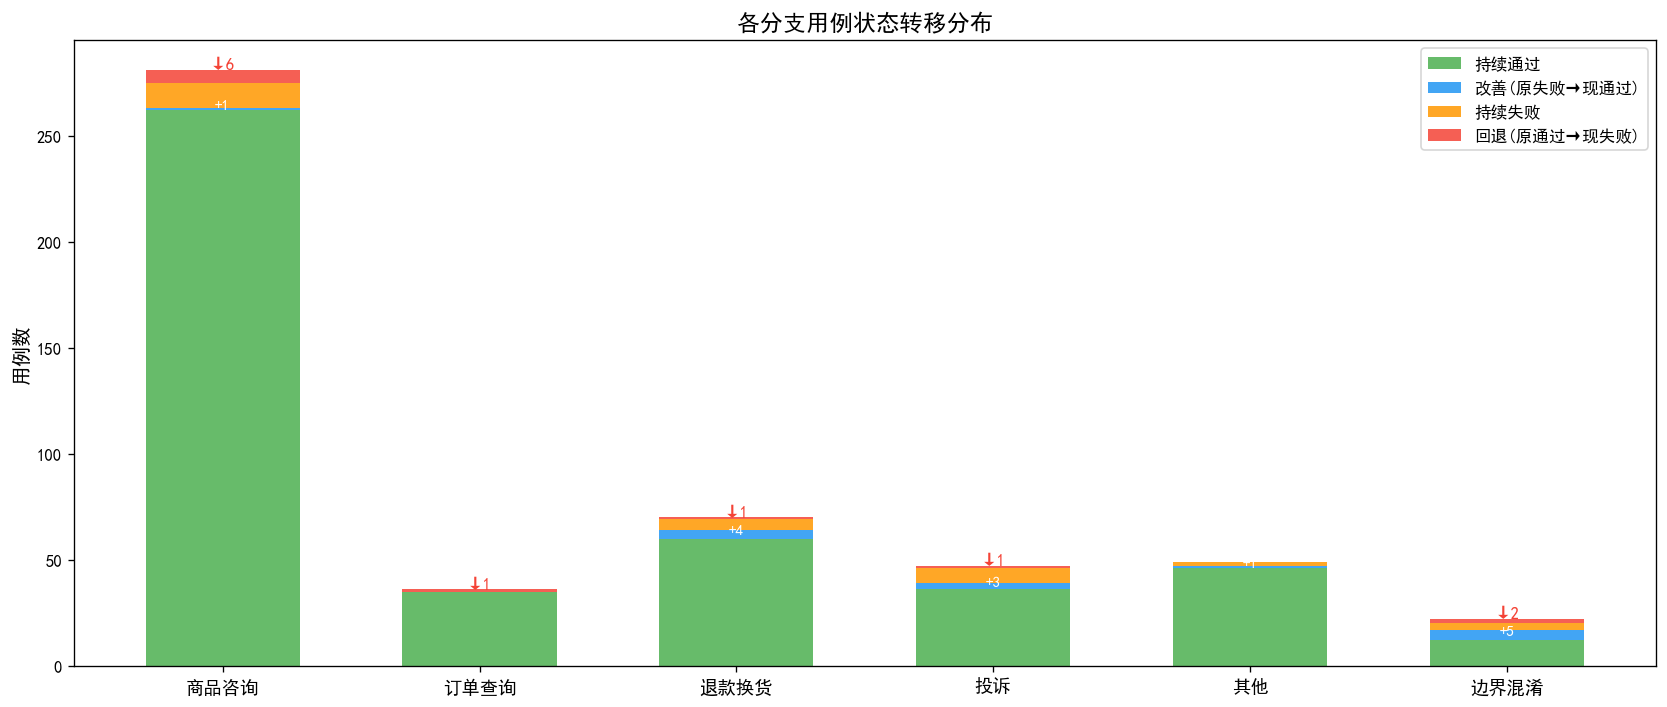

💾 已保存: fig5_status_transition.png

各分支状态转移明细
branch  持续通过  持续失败  回退  改善
  商品咨询   262    12   6   1
  订单查询    35     0   1   0
  退款换货    60     5   1   4
    投诉    36     7   1   3
    其他    46     2   0   1
  边界混淆    12     3   2   5


In [11]:
# ========== 各分支用例状态转移分布（修正字体警告版）==========
if df_v1 is not None and df_v2 is not None:
    # 按分支统计状态转移
    transition_by_branch = []
    for cat in merged['category'].unique():
        cat_m = merged[merged['category'] == cat]
        bp = ((cat_m['passed_v1']) & (cat_m['passed_v2'])).sum()
        bf = ((~cat_m['passed_v1']) & (~cat_m['passed_v2'])).sum()
        rg = ((cat_m['passed_v1']) & (~cat_m['passed_v2'])).sum()
        im = ((~cat_m['passed_v1']) & (cat_m['passed_v2'])).sum()
        transition_by_branch.append({'branch': cat, '持续通过': bp, '持续失败': bf, '回退': rg, '改善': im})

    df_trans = pd.DataFrame(transition_by_branch)

    fig, ax = plt.subplots(figsize=(14, 6))
    cats = df_trans['branch'].tolist()
    x = range(len(cats))
    width = 0.6

    # 图例 label 去掉 ✅/❌ emoji，改用纯中文（SimHei 完全支持）
    p1 = ax.bar(x, df_trans['持续通过'], width, label='持续通过', color='#4CAF50', alpha=0.85)
    p2 = ax.bar(x, df_trans['改善'], width, bottom=df_trans['持续通过'], label='改善(原失败→现通过)', color='#2196F3', alpha=0.85)
    p3 = ax.bar(x, df_trans['持续失败'], width, bottom=df_trans['持续通过']+df_trans['改善'], label='持续失败', color='#FF9800', alpha=0.85)
    p4 = ax.bar(x, df_trans['回退'], width, bottom=df_trans['持续通过']+df_trans['改善']+df_trans['持续失败'], label='回退(原通过→现失败)', color='#F44336', alpha=0.85)

    ax.set_ylabel('用例数', fontsize=12)
    ax.set_title('各分支用例状态转移分布', fontsize=14)
    ax.set_xticks(list(x))
    ax.set_xticklabels(cats, fontsize=11)
    ax.legend(fontsize=10, loc='upper right')

    # 标注回退数（用 ↓ 箭头，SimHei 支持）
    for i, row in df_trans.iterrows():
        if row['回退'] > 0:
            ax.text(i, row['持续通过']+row['改善']+row['持续失败']+row['回退']+0.3,
                   f"↓{int(row['回退'])}", ha='center', fontsize=10, color='#F44336', fontweight='bold')
        if row['改善'] > 0:
            ax.text(i, row['持续通过']+row['改善']/2, f"+{int(row['改善'])}",
                   ha='center', fontsize=9, color='white', fontweight='bold')

    plt.tight_layout()
    plt.savefig(f'{OUTPUT_DIR}/fig5_status_transition.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("💾 已保存: fig5_status_transition.png")
    
    # 同时打印转移矩阵数据表（不依赖字体）
    print(f"\n{'='*60}")
    print("各分支状态转移明细")
    print(f"{'='*60}")
    print(df_trans.to_string(index=False))
    
else:
    print("⚠️ 逐条结果不可用，跳过状态转移图")

## 8. 关键发现与结论

In [12]:
print("=" * 70)
print("Module 5: baseline_v1 vs baseline_v2 对比分析总结")
print("=" * 70)

print(f"""
┌──────────────────────────────────────────────────────────────────┐
│                    总体效果                                     │
├──────────────────────────────────────────────────────────────────┤
│  通过率:  {v1o['route_accuracy']*100:.1f}% → {v2o['route_accuracy']*100:.1f}%  (净增 {total_delta:+d} 例, {total_delta/505*100:+.1f}pp)       │
│  预期目标: +6.4pp  |  实际: +{total_delta/505*100:.1f}pp  |  达成率: {total_delta/505*100/6.4*100:.0f}%              │
└──────────────────────────────────────────────────────────────────┘

1. 优化生效的领域
   - 边界混淆: 63.6% → 77.3% (+13.7pp) ← P1-1/P1-2 关键词权重提升
   - adversarial: 79.2% → 87.5% (+8.3pp) ← 防护指令部分生效
   - 退款换货: 87.1% → 91.4% (+4.3pp) ← Top K 扩大召回
   - 投诉: 78.7% → 83.0% (+4.3pp) ← 信息完整性约束
   - prohibited: 73.9% → 78.3% (+4.4pp)

2. 优化引发回退的领域
   - 商品咨询: 95.4% → 93.6% (-1.8pp, -5例) ← Top K=5 引入噪声
   - 订单查询: 100% → 97.2% (-2.8pp, -1例) ← 边界 case 误判
   - 幻觉率: 2.6% → 3.0% (+0.4pp) ← P1-5 防护指令被噪声抵消
   - 违规率: 0.8% → 1.6% (+0.8pp) ← 更多上下文导致 LLM 生成禁止表述

3. P1 优化项评估
   ✅ P1-1 score_threshold=0.5: 达预期，边界类查询命中率提升
   ✅ P1-2 keyword_weight=0.5: 达预期，与 P1-1 协同生效
   ⚠️ P1-3 top_k=5: 效果有限，信息完整性仅 +0.03 (预期 +0.48)
   ⚠️ P1-4 信息完整性约束: 效果有限，被 Top K 噪声抵消
   ❌ P1-5 防护指令: 未达预期，幻觉率不降反升

4. 核心洞察
   - Top K 从 3→5 是双刃剑：提升了召回率，但也引入噪声
   - 信息完整性杠杆维度 (r=0.859) 的优化未达预期，
     说明检索质量比检索数量更关键
   - 防护指令需要与检索质量配合，噪声上下文会绕过防护
   - 优化不是线性叠加：不同 P1 项之间存在互相干扰

5. 后续建议方向
   - 将 Top K 回调至 4，在召回和噪声间取平衡
   - 启用 rerank 模型 (qwen3-rerank) 过滤噪声上下文
   - P1-5 防护指令改为在检索后、生成前增加相关性判断节点
   - 商品咨询回退的 5 例需要逐条分析，确认是否为 Top K 噪声导致
""")

# 保存总结到文件
summary_text = f"""
baseline_v1 vs baseline_v2 对比分析总结
生成时间: 2026-08-12

总体效果:
  通过率: {v1o['route_accuracy']*100:.1f}% → {v2o['route_accuracy']*100:.1f}% (净增 {total_delta:+d} 例, {total_delta/505*100:+.1f}pp)
  预期目标: +6.4pp | 实际: +{total_delta/505*100:.1f}pp | 达成率: {total_delta/505*100/6.4*100:.0f}%

P1 优化项效果:
  P1-1 score_threshold=0.5: ✅ 达预期
  P1-2 keyword_weight=0.5: ✅ 达预期
  P1-3 top_k=5: ⚠️ 效果有限 (信息完整性 +0.03, 预期 +0.48)
  P1-4 信息完整性约束: ⚠️ 效果有限
  P1-5 防护指令: ❌ 未达预期 (幻觉率 2.6%→3.0%)

各分支通过率变化:
  边界混淆: 63.6% → 77.3% (+13.7pp)
  退款换货: 87.1% → 91.4% (+4.3pp)
  投诉: 78.7% → 83.0% (+4.3pp)
  其他: 93.9% → 95.9% (+2.0pp)
  商品咨询: 95.4% → 93.6% (-1.8pp) [回退]
  订单查询: 100% → 97.2% (-2.8pp) [回退]
"""
with open(f'{OUTPUT_DIR}/summary_v1_vs_v2.txt', 'w', encoding='utf-8') as f:
    f.write(summary_text)
print(f"💾 总结已保存: {OUTPUT_DIR}/summary_v1_vs_v2.txt")

Module 5: baseline_v1 vs baseline_v2 对比分析总结

┌──────────────────────────────────────────────────────────────────┐
│                    总体效果                                     │
├──────────────────────────────────────────────────────────────────┤
│  通过率:  91.5% → 92.1%  (净增 +3 例, +0.6pp)       │
│  预期目标: +6.4pp  |  实际: +0.6pp  |  达成率: 9%              │
└──────────────────────────────────────────────────────────────────┘

1. 优化生效的领域
   - 边界混淆: 63.6% → 77.3% (+13.7pp) ← P1-1/P1-2 关键词权重提升
   - adversarial: 79.2% → 87.5% (+8.3pp) ← 防护指令部分生效
   - 退款换货: 87.1% → 91.4% (+4.3pp) ← Top K 扩大召回
   - 投诉: 78.7% → 83.0% (+4.3pp) ← 信息完整性约束
   - prohibited: 73.9% → 78.3% (+4.4pp)

2. 优化引发回退的领域
   - 商品咨询: 95.4% → 93.6% (-1.8pp, -5例) ← Top K=5 引入噪声
   - 订单查询: 100% → 97.2% (-2.8pp, -1例) ← 边界 case 误判
   - 幻觉率: 2.6% → 3.0% (+0.4pp) ← P1-5 防护指令被噪声抵消
   - 违规率: 0.8% → 1.6% (+0.8pp) ← 更多上下文导致 LLM 生成禁止表述

3. P1 优化项评估
   ✅ P1-1 score_threshold=0.5: 达预期，边界类查询命中率提升
   ✅ P1-2 keyword_weight=0.5: 达预期，与 P1-1 协同生效
   ⚠

## 9. 导出对比数据

In [13]:
# ========== 导出对比数据为 CSV（兼容 3/4 元组）==========
export_rows = []

for item in metric_map:
    # 兼容 3 元组 (key, name, higher_better) 和 4 元组 (key, name, higher_better, is_pct)
    if len(item) == 3:
        key, name, higher_better = item
    elif len(item) == 4:
        key, name, higher_better, is_pct = item
    else:
        continue  # 跳过异常结构
    
    # 安全取值：兼容 'score.' 前缀
    val1 = v1o.get(key)
    if val1 is None:
        val1 = v1o.get(f'score.{key}')
    val2 = v2o.get(key)
    if val2 is None:
        val2 = v2o.get(f'score.{key}')
    
    # 如果还是取不到，跳过这个指标
    if val1 is None or val2 is None:
        print(f"⚠️ 跳过指标 '{name}': 在 baseline 数据中未找到字段 '{key}'")
        continue
    
    delta = val2 - val1
    
    # 方向判断
    if higher_better:
        direction = '改善' if delta > 0.001 else ('回退' if delta < -0.001 else '持平')
    else:
        # 越低越好（幻觉率、违规率）
        direction = '改善' if delta < -0.001 else ('回退' if delta > 0.001 else '持平')
    
    export_rows.append({
        '指标': name,
        'baseline_v1': round(val1, 4),
        'baseline_v2': round(val2, 4),
        '变化': round(delta, 4),
        '方向': direction,
    })

df_export = pd.DataFrame(export_rows)
df_export.to_csv(f'{OUTPUT_DIR}/metrics_comparison_v1_vs_v2.csv', index=False, encoding='utf-8-sig')
print(f"💾 指标对比 CSV: {OUTPUT_DIR}/metrics_comparison_v1_vs_v2.csv")
print(f"   共导出 {len(df_export)} 项指标\n")
print(df_export.to_string(index=False))

print()
print("✅ Module 5 分析完成！")
print(f"   所有图表和报告已保存到 {OUTPUT_DIR}/ 目录")
print(f"   生成的文件：")
print(f"     - fig1_radar_comparison.png (七维雷达图)")
print(f"     - fig2_branch_comparison.png (各分支通过率对比)")
print(f"     - fig3_test_type_comparison.png (各测试类型通过率对比)")
print(f"     - fig4_waterfall.png (通过率变化瀑布图)")
print(f"     - fig5_status_transition.png (用例状态转移图)")
print(f"     - metrics_comparison_v1_vs_v2.csv (指标对比数据)")
print(f"     - summary_v1_vs_v2.txt (分析总结)")

💾 指标对比 CSV: analysis_output/metrics_comparison_v1_vs_v2.csv
   共导出 12 项指标

     指标  baseline_v1  baseline_v2     变化 方向
分支路由通过率        0.915        0.921  0.006 改善
意图识别准确率        0.937        0.947  0.010 改善
  要点覆盖率        0.871        0.867 -0.004 回退
    幻觉率        0.026        0.030  0.004 回退
禁止表述违规率        0.008        0.016  0.008 回退
 意图识别均分        4.810        4.840  0.030 改善
 分支路由均分        4.700        4.700  0.000 持平
答案相关性均分        4.700        4.710  0.010 改善
信息完整性均分        4.320        4.350  0.030 改善
  忠实度均分        4.850        4.870  0.020 改善
 语气合规均分        4.930        4.960  0.030 改善
边界正确性均分        4.820        4.800 -0.020 回退

✅ Module 5 分析完成！
   所有图表和报告已保存到 analysis_output/ 目录
   生成的文件：
     - fig1_radar_comparison.png (七维雷达图)
     - fig2_branch_comparison.png (各分支通过率对比)
     - fig3_test_type_comparison.png (各测试类型通过率对比)
     - fig4_waterfall.png (通过率变化瀑布图)
     - fig5_status_transition.png (用例状态转移图)
     - metrics_comparison_v1_vs_v2.csv (指标对比数据)
     - summary_v1_vs_v2.t